# 04 Classification Modeling — Promise Band

Predict under_half, half_to_full or late. Compare fixed models and select Logistic Regression parameters using forward temporal cross-validation within the original Train set. Freeze candidates before validation and revised Test evaluation.

## 0. Setup and Load Data

Read the latest processed feature table and selected_features.csv exported by notebook 03.


In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from scipy.sparse import csr_matrix
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, matthews_corrcoef, precision_recall_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "data" / "processed" / "promise_band_feature_table.csv").exists():
        ROOT = candidate
        break
DATA = ROOT / "data" / "processed"
RANDOM_STATE = 42
TARGET = "promise_band"
BANDS = ["under_half", "half_to_full", "late"]
pd.set_option("display.max_columns", None)

df = pd.read_csv(DATA / "promise_band_feature_table.csv", parse_dates=[
    "order_purchase_timestamp", "order_delivered_customer_date",
])
selected_features = pd.read_csv(DATA / "selected_features.csv")
print("Dataset shape:", df.shape)


Dataset shape: (96470, 79)


## 1. Prepare Train / Validation / Test

Keep the existing temporal split: train 64,429; validation 12,541; test 14,471. The 5,029 excluded orders do not enter training or evaluation.

In [2]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

assert df["split"].value_counts().to_dict() == {
    "train": 64429, "val": 12541, "test": 14471, "excluded": 5029,
}
assert df["order_id"].is_unique and df[TARGET].notna().all()
assert set(df[TARGET]) == set(BANDS)
assert train_df["order_purchase_timestamp"].max() < val_df["order_purchase_timestamp"].min()
assert val_df["order_purchase_timestamp"].max() < test_df["order_purchase_timestamp"].min()
assert train_df["order_delivered_customer_date"].lt(val_df["order_purchase_timestamp"].min()).all()
assert val_df["order_delivered_customer_date"].lt(test_df["order_purchase_timestamp"].min()).all()

splits = {"Val": val_df, "Test": test_df}
split_summary = pd.DataFrame([
    {"split": name, "n": len(frame), **{
        f"{band} (%)": frame[TARGET].eq(band).mean() * 100 for band in BANDS
    }}
    for name, frame in [("Train", train_df), *splits.items()]
])
display(split_summary.round(2))
print("Excluded (not used):", df["split"].eq("excluded").sum())


,split,n,under_half (%),half_to_full (%),late (%)
0,Train,64429,55.25,37.94,6.81
1,Val,12541,70.54,25.17,4.28
2,Test,14471,60.74,34.98,4.28


Excluded (not used): 5029


## 2. Load Selected Features

Read the complete selected_features.csv list in saved rank order. Feature count is determined by the CSV; do not repeat feature selection. The upstream candidate table excludes raw latitude and longitude while retaining distance and regional representations.


In [3]:
features = selected_features.sort_values("rank", kind="stable")["feature"].tolist()
assert features and len(features) == len(set(features))
assert set(features).issubset(df.columns)
assert not set(features).intersection({
    TARGET, "split", "order_id", "customer_unique_id", "seller_id",
    "actual_days", "duration_ratio", "order_purchase_timestamp",
    "order_delivered_customer_date", "order_delivered_carrier_date",
    "order_status", "order_approved_at", "review_score",
})

X_train = train_df[features]
y_train = train_df[TARGET]
print("Selected features:", len(features))
print(features)


Selected features: 10
['promised_days', 'route_prior_mean_ratio', 'distance_km', 'route_prior_delivered', 'purchase_month', 'same_state', 'customer_state', 'category_prior_delivered', 'seller_prior_mean_ratio', 'market_30d_late_rate']


## 3. Build Preprocessing

Use the same categorical field definitions as notebook 03, including purchase_month and purchase_dow even when stored as integers. Only selected fields enter the model. Median imputation handles numeric features; most-frequent imputation and one-hot encoding handle categorical features. Scale numeric inputs for LR only. Refit preprocessing inside every CV training Pipeline and on the original Train rows for subsequent evaluation.


In [4]:
CAT_COLS = ["customer_state", "seller_state", "product_category", "purchase_dow", "purchase_month"]
categorical_features = [f for f in features if f in CAT_COLS]
numeric_features = [f for f in features if f not in CAT_COLS]

def build_preprocessor(scale=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_features),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_features),
    ], remainder="drop", sparse_threshold=0)

logistic_preprocessor = build_preprocessor(scale=True)
tree_preprocessor = build_preprocessor()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['promised_days', 'route_prior_mean_ratio', 'distance_km', 'route_prior_delivered', 'same_state', 'category_prior_delivered', 'seller_prior_mean_ratio', 'market_30d_late_rate']
Categorical features: ['purchase_month', 'customer_state']


### Shared Evaluation Helper

Late AP is Average Precision for late versus the other two classes, using the probability column identified from classes_. Mean CV validation late AP is the primary selection metric; retain Macro-F1, other overall metrics and late precision/recall/F1 as complementary measures. AP is not trapezoidal PR-curve area.


In [5]:
def evaluate_classifier(model, X, y):
    pred = model.predict(X)
    late_column = np.flatnonzero(np.asarray(model.classes_) == "late").item()
    late_probability = model.predict_proba(X)[:, late_column]
    report = classification_report(y, pred, labels=BANDS, output_dict=True, zero_division=0)
    return {
        "Late AP": average_precision_score(y.eq("late"), late_probability),
        "Accuracy": accuracy_score(y, pred),
        "Macro-F1": f1_score(y, pred, labels=BANDS, average="macro", zero_division=0),
        "Weighted-F1": f1_score(y, pred, labels=BANDS, average="weighted", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y, pred),
        "MCC": matthews_corrcoef(y, pred),
        "Late Precision": report["late"]["precision"],
        "Late Recall": report["late"]["recall"],
        "Late F1": report["late"]["f1-score"],
        "report": pd.DataFrame({band: report[band] for band in BANDS}).T,
        "matrix": confusion_matrix(y, pred, labels=BANDS),
    }


## 4. Baseline Models

Dummy uses the majority class; plain LR and the single tree use class_weight=None.

In [6]:
dummy_model = DummyClassifier(strategy="most_frequent")

logistic_model = Pipeline([
    ("preprocessor", logistic_preprocessor),
    ("model", LogisticRegression(
        C=1.0, penalty="l2", solver="lbfgs", max_iter=1000,
        class_weight=None, random_state=RANDOM_STATE,
    )),
])

decision_tree_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", DecisionTreeClassifier(class_weight=None, random_state=RANDOM_STATE)),
])


## 5. Temporal Cross-Validation and LR Tuning

Sort the original Train orders by purchase time and divide their complete purchase dates into four consecutive blocks. Use block 1 to predict block 2, blocks 1?2 to predict block 3, and blocks 1?3 to predict block 4. At each validation start, retain only earlier orders already delivered; missing delivery times are ineligible.

Clone and fit a fresh preprocessing/model Pipeline for every configuration and fold. Keep the original C grid (0.01, 0.1, 0.5, 1, 2, 5, 10), custom late weights (1, 1.25, 1.5, 2, 2.5, 3, 4, 5), and balanced reference. Weight 1 equals None; use L2/lbfgs, max_iter=4000 and random_state=42. No adaptive refinement or CV threshold search.

Rank the overall candidate by mean CV validation late AP, with mean Macro-F1, MCC and balanced accuracy as tie-breakers. Retain the late-sensitive candidate's original reference-relative eligibility constraints, but rank eligible configurations by mean late AP before the original tie-breakers. AP is computed separately in each fold and averaged without pooling predictions. All original Validation and Test orders remain outside CV. The features were selected in advance by 03 and are held fixed across folds; this is not nested feature selection. Test has been viewed historically and is used only for revised evaluation after parameter freezing.

After CV selection, refit candidates on the original Train rows and freeze their Validation thresholds before calculating any revised Test scores. Threshold selection retains the assumed precision floor and tie rule described in Section 12.1.


In [7]:
purchase_col = "order_purchase_timestamp"
delivery_col = "order_delivered_customer_date"
cv_train = train_df.sort_values([purchase_col, "order_id"]).reset_index(drop=True)
purchase_dates = cv_train[purchase_col].dt.normalize()
date_blocks = np.array_split(np.sort(purchase_dates.unique()), 4)
assert all(len(block) > 0 for block in date_blocks)
temporal_folds, fold_rows = [], []
for fold in range(1, 4):
    start = pd.Timestamp(date_blocks[fold][0])
    end = pd.Timestamp(date_blocks[fold][-1]) + pd.Timedelta(days=1)
    earlier = purchase_dates.lt(start)
    mature = cv_train[delivery_col].notna() & cv_train[delivery_col].lt(start)
    train_idx = np.flatnonzero(earlier & mature)
    val_idx = np.flatnonzero(purchase_dates.ge(start) & purchase_dates.lt(end))
    ft, fv = cv_train.iloc[train_idx], cv_train.iloc[val_idx]
    assert ft[purchase_col].max() < start <= fv[purchase_col].min()
    assert ft[delivery_col].lt(start).all()
    assert set(ft[TARGET]) == set(fv[TARGET]) == set(BANDS)
    assert set(ft["order_id"]).isdisjoint(fv["order_id"])
    temporal_folds.append((train_idx, val_idx))
    row = {
        "Fold": fold, "Train start": ft[purchase_col].min(),
        "Train end": ft[purchase_col].max(), "Validation start": fv[purchase_col].min(),
        "Validation end": fv[purchase_col].max(), "Training cutoff": start,
        "Train n": len(ft), "Validation n": len(fv),
        "Maturity exclusions": int((earlier & ~mature).sum()),
        "Missing delivery exclusions": int((earlier & cv_train[delivery_col].isna()).sum()),
    }
    for label, frame in [("Train", ft), ("Validation", fv)]:
        for band in BANDS:
            row[f"{label} {band} n"] = int(frame[TARGET].eq(band).sum())
        row[f"{label} late %"] = 100 * frame[TARGET].eq("late").mean()
    fold_rows.append(row)
fold_summary = pd.DataFrame(fold_rows)
display(fold_summary.round(3))

C_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
weight_values = ["None", "Balanced", 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
CV_METRICS = ["Late AP", "Accuracy", "Macro-F1", "Weighted-F1", "Balanced Acc", "MCC",
              "Late Precision", "Late Recall", "Late F1"]

def lr_class_weight(weight):
    return (None if weight == "None" else "balanced" if weight == "Balanced" else
            {"under_half": 1.0, "half_to_full": 1.0, "late": float(weight)})

def fit_cv_configuration(key):
    C, weight = key
    rows = []
    for fold, (train_idx, val_idx) in enumerate(temporal_folds, 1):
        ft, fv = cv_train.iloc[train_idx], cv_train.iloc[val_idx]
        model = clone(logistic_model).set_params(
            model__C=C, model__class_weight=lr_class_weight(weight), model__max_iter=4000,
        )
        started = perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(ft[features], ft[TARGET])
        fit_seconds = perf_counter() - started
        for split, frame in [("Train", ft), ("Validation", fv)]:
            result = evaluate_classifier(model, frame[features], frame[TARGET])
            rows.append({
                "C": C, "Weight": weight, "Fold": fold, "Split": split,
                "n": len(frame), "Fit seconds": fit_seconds,
                "Iterations": int(model.named_steps["model"].n_iter_.max()),
                **{metric: result[metric] for metric in CV_METRICS},
            })
    return rows

cv_keys = [(C, weight) for C in C_values for weight in weight_values]
cv_records = []
cv_started = perf_counter()
with ThreadPoolExecutor(max_workers=4) as executor:
    for rows in executor.map(fit_cv_configuration, cv_keys):
        cv_records.extend(rows)
cv_seconds = perf_counter() - cv_started
cv_fold_results = pd.DataFrame(cv_records)
tuning_results = cv_fold_results.loc[
    cv_fold_results["Split"].eq("Validation")
].groupby(["C", "Weight"], sort=False)[CV_METRICS].agg(["mean", "std"])
tuning_results.columns = [f"{metric} {stat}" for metric, stat in tuning_results.columns]
tuning_results = tuning_results.reset_index()
tuning_results["Business Score"] = (
    2 * tuning_results["Macro-F1 mean"] * tuning_results["Late F1 mean"]
    / (tuning_results["Macro-F1 mean"] + tuning_results["Late F1 mean"])
)
overall = tuning_results.sort_values(
    ["Late AP mean", "Macro-F1 mean", "MCC mean", "Balanced Acc mean"],
    ascending=False, kind="stable",
).iloc[0]
plain_reference = tuning_results.loc[
    tuning_results["C"].eq(1) & tuning_results["Weight"].eq("None")
].iloc[0]
balanced_reference = tuning_results.loc[
    tuning_results["C"].eq(1) & tuning_results["Weight"].eq("Balanced")
].iloc[0]
eligible = tuning_results.loc[
    tuning_results["Macro-F1 mean"].ge(balanced_reference["Macro-F1 mean"])
    & tuning_results["Late Precision mean"].gt(balanced_reference["Late Precision mean"])
    & tuning_results["Late Recall mean"].gt(plain_reference["Late Recall mean"])
    & tuning_results["Late F1 mean"].gt(plain_reference["Late F1 mean"])
]
business = (None if eligible.empty else eligible.sort_values(
    ["Late AP mean", "Business Score", "Macro-F1 mean", "Late Precision mean"],
    ascending=False, kind="stable",
).iloc[0])
candidate_rows = {"Candidate A": overall}
if business is not None:
    candidate_rows["Candidate B"] = business
else:
    print("No late-sensitive configuration meets the unchanged CV business rule.")
display(tuning_results.sort_values(
    ["Late AP mean", "Macro-F1 mean", "MCC mean", "Balanced Acc mean"],
    ascending=False, kind="stable",
).head(10).round(4))
print("Configurations:", len(cv_keys), "| Fold fits:", len(cv_keys) * len(temporal_folds),
      "| CV seconds:", round(cv_seconds, 2))
print("Frozen candidates:", {name: {"C": float(row["C"]), "Weight": row["Weight"]}
                             for name, row in candidate_rows.items()})

candidate_models, refitted_models = {}, {}
for label, row in candidate_rows.items():
    key = (float(row["C"]), row["Weight"])
    if key not in refitted_models:
        model = clone(logistic_model).set_params(
            model__C=key[0], model__class_weight=lr_class_weight(key[1]), model__max_iter=4000,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(X_train, y_train)
        refitted_models[key] = model
    model = refitted_models[key]
    candidate_models[label] = model

MIN_LATE_PRECISION = 0.20
MIN_LATE_RECALL = 0.30

threshold_choices, validation_scores = {}, {}
threshold_selection_rows = []
for label, model in candidate_models.items():
    classes = np.asarray(model.classes_)
    late_column = np.flatnonzero(classes == "late").item()
    probabilities = model.predict_proba(val_df[features])
    validation_scores[label] = (classes, probabilities)
    precision, recall, thresholds = precision_recall_curve(
        val_df[TARGET].eq("late"), probabilities[:, late_column],
    )
    feasible = np.flatnonzero(precision[:-1] >= MIN_LATE_PRECISION)
    threshold = None
    if len(feasible):
        best_recall = recall[feasible].max()
        tied = feasible[recall[feasible] == best_recall]
        threshold = float(thresholds[tied].max())
    threshold_choices[label] = threshold
    threshold_selection_rows.append({
        "Candidate": label, "Feasible precision threshold": threshold is not None,
        "Frozen threshold": threshold,
    })



,Fold,Train start,Train end,Validation start,Validation end,Training cutoff,Train n,Validation n,Maturity exclusions,Missing delivery exclusions,Train under_half n,Train half_to_full n,Train late n,Train late %,Validation under_half n,Validation half_to_full n,Validation late n,Validation late %
0,1,2016-09-15 12:16:38,2017-04-18 12:41:40,2017-04-24 00:15:05,2017-08-20 22:08:30,2017-04-24,5900,13926,975,0,4426,1351,123,2.085,8826,4677,423,3.037
1,2,2016-09-15 12:16:38,2017-08-17 22:17:09,2017-08-21 00:01:09,2017-12-16 23:59:58,2017-08-21,19121,20948,1680,0,12696,5865,560,2.929,10692,8622,1634,7.800
2,3,2016-09-15 12:16:38,2017-12-15 12:12:12,2017-12-17 00:39:23,2018-04-13 13:01:55,2017-12-17,37953,22680,3796,0,23229,13425,1299,3.423,11396,9257,2027,8.937


,C,Weight,Late AP mean,Late AP std,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Weighted-F1 std,Balanced Acc mean,Balanced Acc std,MCC mean,MCC std,Late Precision mean,Late Precision std,Late Recall mean,Late Recall std,Late F1 mean,Late F1 std,Business Score
5,0.01,2.5,0.1023,0.0714,0.5770,0.0456,0.3321,0.0068,0.5028,0.0566,0.3701,0.0092,0.1386,0.0299,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.01,2.0,0.1021,0.0719,0.5764,0.0456,0.3309,0.0069,0.5015,0.0565,0.3695,0.0093,0.1369,0.0307,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6,0.01,3.0,0.1021,0.0704,0.5773,0.0453,0.3332,0.0062,0.5040,0.0559,0.3706,0.0095,0.1392,0.0303,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.01,1.5,0.1020,0.0729,0.5760,0.0456,0.3300,0.0074,0.5003,0.0570,0.3690,0.0093,0.1360,0.0311,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.01,1.25,0.1018,0.0731,0.5759,0.0457,0.3299,0.0081,0.5001,0.0576,0.3690,0.0090,0.1360,0.0305,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,0.01,4.0,0.1012,0.0678,0.5773,0.0452,0.3353,0.0058,0.5058,0.0552,0.3713,0.0100,0.1393,0.0293,0.0972,0.1684,0.0012,0.0020,0.0023,0.0039,0.0045
0,0.01,None,0.1011,0.0728,0.5754,0.0458,0.3291,0.0084,0.4992,0.0579,0.3685,0.0089,0.1347,0.0304,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,0.01,5.0,0.1001,0.0656,0.5764,0.0456,0.3392,0.0071,0.5067,0.0555,0.3727,0.0113,0.1395,0.0282,0.1457,0.1263,0.0075,0.0119,0.0137,0.0216,0.0263
9,0.10,None,0.0955,0.0576,0.5332,0.0076,0.3302,0.0191,0.4864,0.0411,0.3597,0.0154,0.0911,0.0627,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
11,0.10,1.25,0.0934,0.0545,0.5337,0.0087,0.3316,0.0170,0.4877,0.0390,0.3606,0.0155,0.0932,0.0632,0.0667,0.1155,0.0005,0.0009,0.0010,0.0017,0.0020


Configurations: 63 | Fold fits: 189 | CV seconds: 139.78
Frozen candidates: {'Candidate A': {'C': 0.01, 'Weight': 2.5}, 'Candidate B': {'C': 0.01, 'Weight': 'Balanced'}}


## 6. Baseline Results

After freezing CV-selected parameters, fit the fixed baselines on the original Train set and report Validation and revised Test results. Full reports are collected in Section 9.

In [8]:
models = {
    "Dummy": dummy_model,
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
}
for model in models.values():
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model.fit(X_train, y_train)

results = {}
metric_rows, comparison_rows, report_rows = [], [], []
for name, model in models.items():
    comparison_row = {"Model": name}
    for split, frame in splits.items():
        result = evaluate_classifier(model, frame[features], frame[TARGET])
        results[name, split] = result
        metrics = {k: v for k, v in result.items() if k not in ("report", "matrix")}
        metric_rows.append({"Model": name, "Split": split, **metrics})
        comparison_row.update({f"{split} {k}": v for k, v in metrics.items()
                               if k not in ("Accuracy", "Weighted-F1")})
        report_rows.append(result["report"].assign(Model=name, Split=split))
    comparison_rows.append(comparison_row)

all_metrics = pd.DataFrame(metric_rows)
per_class = pd.concat(report_rows).rename_axis("Class").reset_index()

comparison = pd.DataFrame(comparison_rows)[[
    "Model", "Val Late AP", "Test Late AP", "Val Macro-F1", "Test Macro-F1", "Val Balanced Acc", "Test Balanced Acc",
    "Val MCC", "Test MCC", "Val Late Precision", "Val Late Recall", "Val Late F1",
    "Test Late Precision", "Test Late Recall", "Test Late F1",
]]
display(all_metrics.loc[all_metrics["Split"].eq("Val"),
    ["Model", "Late AP", "Macro-F1", "Late Precision", "Late Recall", "Late F1"]].round(4))


,Model,Late AP,Macro-F1,Late Precision,Late Recall,Late F1
0,Dummy,0.0428,0.2758,0.0000,0.0000,0.0000
2,Logistic Regression,0.1243,0.4007,1.0000,0.0019,0.0037
4,Decision Tree,0.0442,0.3569,0.0609,0.0782,0.0685


Dummy's Validation late AP equals the late prevalence (0.0428). Plain LR achieves AP=0.1243 and Macro-F1=0.4007, compared with the single tree's AP=0.0442 and Macro-F1=0.3569. Plain LR's argmax late recall is only 0.0019; high precision based on very few alerts does not establish effective late detection. Probability ranking and the operating point require separate interpretation.


## 7. Class Imbalance Experiment

Clone LR and the single tree, changing only class_weight from None to balanced. No resampling or other parameter changes.

In [9]:
balanced_logistic_model = clone(logistic_model).set_params(model__class_weight="balanced")
balanced_tree_model = clone(decision_tree_model).set_params(model__class_weight="balanced")

for model in [balanced_logistic_model, balanced_tree_model]:
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model.fit(X_train, y_train)

weighting_models = {
    ("Logistic Regression", "None"): logistic_model,
    ("Logistic Regression", "Balanced"): balanced_logistic_model,
    ("Decision Tree", "None"): decision_tree_model,
    ("Decision Tree", "Balanced"): balanced_tree_model,
}
weighting_results = {}
weighting_metric_rows, weighting_report_rows, weighting_comparison_rows = [], [], []
for (name, weight), model in weighting_models.items():
    row = {"Model": name, "Class Weight": weight}
    for split, frame in splits.items():
        result = (results[name, split] if weight == "None" else
                  evaluate_classifier(model, frame[features], frame[TARGET]))
        weighting_results[name, weight, split] = result
        metrics = {k: v for k, v in result.items() if k not in ("report", "matrix")}
        weighting_metric_rows.append({"Model": name, "Class Weight": weight, "Split": split, **metrics})
        weighting_report_rows.append(result["report"].assign(Model=name, Weight=weight, Split=split))
        row.update({f"{split} {k}": v for k, v in metrics.items()
                    if k not in ("Accuracy", "Weighted-F1", "MCC")})
    weighting_comparison_rows.append(row)

weighting_metrics = pd.DataFrame(weighting_metric_rows)
weighting_per_class = pd.concat(weighting_report_rows).rename_axis("Class").reset_index()

weighting_comparison = pd.DataFrame(weighting_comparison_rows)[[
    "Model", "Class Weight", "Val Late AP", "Test Late AP", "Val Macro-F1", "Test Macro-F1", "Val Balanced Acc", "Test Balanced Acc",
    "Val Late Precision", "Val Late Recall", "Val Late F1",
    "Test Late Precision", "Test Late Recall", "Test Late F1",
]]
display(weighting_comparison[['Model', 'Class Weight', 'Val Late AP', 'Val Macro-F1', 'Val Late Precision', 'Val Late Recall', 'Val Late F1']].round(4))


,Model,Class Weight,Val Late AP,Val Macro-F1,Val Late Precision,Val Late Recall,Val Late F1
0,Logistic Regression,None,0.1243,0.4007,1.0000,0.0019,0.0037
1,Logistic Regression,Balanced,0.1222,0.4453,0.1899,0.1397,0.1609
2,Decision Tree,None,0.0442,0.3569,0.0609,0.0782,0.0685
3,Decision Tree,Balanced,0.0427,0.3524,0.0394,0.0466,0.0427


Balanced LR changes Validation late AP from 0.1243 to 0.1222 and Macro-F1 from 0.4007 to 0.4453. Late recall rises from 0.0019 to 0.1397, while precision changes from 1.0000 to 0.1899. The increase in default-rule recall therefore does not imply improved risk ranking. These fixed-reference results do not alter CV selection.


## 8. Advanced Models

Compare RF None, RF Balanced and HGB using the same unscaled, train-fitted preprocessing. RF uses 300 trees; its versions differ only in class_weight. HGB retains its fixed configuration without sample weighting.

In [10]:
random_forest_model = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, class_weight=None,
    )),
])

balanced_forest_model = clone(random_forest_model).set_params(model__class_weight="balanced")

hist_gradient_boosting_model = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
])

advanced_models = {
    ("Random Forest", "None"): random_forest_model,
    ("Random Forest", "Balanced"): balanced_forest_model,
    ("HistGradientBoosting", "None"): hist_gradient_boosting_model,
}
for model in advanced_models.values():
    model.fit(X_train, y_train)


Validation late AP is 0.0933 for unweighted RF, 0.0741 for balanced RF and 0.0776 for HGB, below plain LR's 0.1243. These fixed comparisons provide context; they do not reopen the LR grid or frozen CV candidate rules.


## 9. Unified Model Comparison

Report all eight fixed models, with late AP, accuracy, weighted-F1 and per-class precision/recall/F1/support for both splits. These post-selection results do not reopen the frozen CV search.

In [11]:
combined_results = dict(weighting_results)
for split in splits:
    combined_results["Dummy", "None", split] = results["Dummy", split]
for (name, weight), model in advanced_models.items():
    for split, frame in splits.items():
        combined_results[name, weight, split] = evaluate_classifier(model, frame[features], frame[TARGET])

combined_model_keys = [("Dummy", "None"), *weighting_models, *advanced_models]
combined_metric_rows, combined_report_rows, combined_comparison_rows = [], [], []
for name, weight in combined_model_keys:
    row = {"Model": name, "Weight": weight}
    for split in splits:
        result = combined_results[name, weight, split]
        metrics = {k: v for k, v in result.items() if k not in ("report", "matrix")}
        combined_metric_rows.append({"Model": name, "Weight": weight, "Split": split, **metrics})
        combined_report_rows.append(result["report"].assign(Model=name, Weight=weight, Split=split))
        row.update({f"{split} {k}": v for k, v in metrics.items()
                    if k not in ("Accuracy", "Weighted-F1")})
    combined_comparison_rows.append(row)

combined_metrics = pd.DataFrame(combined_metric_rows)
combined_per_class = pd.concat(combined_report_rows).rename_axis("Class").reset_index()

combined_comparison = pd.DataFrame(combined_comparison_rows)[[
    "Model", "Weight", "Val Late AP", "Test Late AP", "Val Macro-F1", "Test Macro-F1", "Val Balanced Acc", "Test Balanced Acc",
    "Val MCC", "Test MCC", "Val Late Precision", "Val Late Recall", "Val Late F1",
    "Test Late Precision", "Test Late Recall", "Test Late F1",
]]
display(combined_comparison.round(4))

display(HTML(
    "<details><summary>Detailed fixed-model metrics and per-class reports</summary>"
    + combined_metrics.round(4).to_html()
    + combined_per_class[["Model", "Weight", "Split", "Class", "precision", "recall", "f1-score", "support"]].round(4).to_html()
    + "</details>"
))


,Model,Weight,Val Late AP,Test Late AP,Val Macro-F1,Test Macro-F1,Val Balanced Acc,Test Balanced Acc,Val MCC,Test MCC,Val Late Precision,Val Late Recall,Val Late F1,Test Late Precision,Test Late Recall,Test Late F1
0,Dummy,None,0.0428,0.0428,0.2758,0.2519,0.3333,0.3333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,Logistic Regression,None,0.1243,0.0762,0.4007,0.3600,0.4048,0.3625,0.2308,0.0708,1.0000,0.0019,0.0037,0.1389,0.0161,0.0289
2,Logistic Regression,Balanced,0.1222,0.0761,0.4453,0.3107,0.4448,0.3891,0.2178,0.0306,0.1899,0.1397,0.1609,0.0685,0.4484,0.1189
3,Decision Tree,None,0.0442,0.0464,0.3569,0.3194,0.3604,0.3616,0.0566,0.0283,0.0609,0.0782,0.0685,0.0549,0.2919,0.0925
4,Decision Tree,Balanced,0.0427,0.0432,0.3524,0.3316,0.3548,0.3502,0.0602,0.0362,0.0394,0.0466,0.0427,0.0464,0.1016,0.0637
5,Random Forest,None,0.0933,0.0454,0.3540,0.3504,0.3659,0.3586,0.1318,0.0681,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6,Random Forest,Balanced,0.0741,0.0570,0.3489,0.3374,0.3621,0.3457,0.1188,0.0313,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,HistGradientBoosting,None,0.0776,0.0404,0.3513,0.3343,0.3607,0.3385,0.1039,0.0153,0.0000,0.0000,0.0000,0.0385,0.0323,0.0351


,Model,Weight,Split,Late AP,Accuracy,Macro-F1,Weighted-F1,Balanced Acc,MCC,Late Precision,Late Recall,Late F1
0,Dummy,None,Val,0.0428,0.7054,0.2758,0.5836,0.3333,0.0000,0.0000,0.0000,0.0000
1,Dummy,None,Test,0.0428,0.6074,0.2519,0.4590,0.3333,0.0000,0.0000,0.0000,0.0000
2,Logistic Regression,None,Val,0.1243,0.7034,0.4007,0.6729,0.4048,0.2308,1.0000,0.0019,0.0037
3,Logistic Regression,None,Test,0.0762,0.5474,0.3600,0.5363,0.3625,0.0708,0.1389,0.0161,0.0289
4,Logistic Regression,Balanced,Val,0.1222,0.6452,0.4453,0.6510,0.4448,0.2178,0.1899,0.1397,0.1609
5,Logistic Regression,Balanced,Test,0.0761,0.4088,0.3107,0.4416,0.3891,0.0306,0.0685,0.4484,0.1189
6,Decision Tree,None,Val,0.0442,0.5556,0.3569,0.5703,0.3604,0.0566,0.0609,0.0782,0.0685
7,Decision Tree,None,Test,0.0464,0.3958,0.3194,0.4362,0.3616,0.0283,0.0549,0.2919,0.0925
8,Decision Tree,Balanced,Val,0.0427,0.5614,0.3524,0.5741,0.3548,0.0602,0.0394,0.0466,0.0427
9,Decision Tree,Balanced,Test,0.0432,0.4396,0.3316,0.4549,0.3502,0.0362,0.0464,0.1016,0.0637


## 10. Cross-Validated Candidate Comparison

The original C/weight grid was evaluated in Section 5 without adaptive refinement. Report each fold's training and validation metrics, together with means and sample standard deviations. Candidate A maximises mean CV validation late AP. Candidate B retains the reference-relative eligibility constraints using CV means and selects the highest mean late AP within that subset. Training late AP is reported alongside validation late AP; all other metrics remain available.

In [12]:
cv_summary = cv_fold_results.groupby(["C", "Weight", "Split"], sort=False)[CV_METRICS].agg(["mean", "std"])
cv_summary.columns = [f"{metric} {stat}" for metric, stat in cv_summary.columns]
cv_summary = cv_summary.reset_index()
candidate_cv_summary = pd.concat([
    cv_summary.loc[cv_summary["C"].eq(row["C"]) & cv_summary["Weight"].eq(row["Weight"])]
    .assign(Candidate=name)
    for name, row in candidate_rows.items()
], ignore_index=True)
candidate_cv_folds = pd.concat([
    cv_fold_results.loc[
        cv_fold_results["C"].eq(row["C"]) & cv_fold_results["Weight"].eq(row["Weight"])
    ].assign(Candidate=name)
    for name, row in candidate_rows.items()
], ignore_index=True)
summary_columns = ["Candidate", "C", "Weight", "Split"]
for metric in CV_METRICS:
    summary_columns.extend([metric + " mean", metric + " std"])
display(candidate_cv_summary[summary_columns].round(4))
display(candidate_cv_folds.round(4))
display(HTML("<details><summary>All configurations: fold training and validation scores</summary>"
             + cv_fold_results.round(4).to_html(index=False) + "</details>"))
display(HTML("<details><summary>All configurations: means and sample standard deviations</summary>"
             + cv_summary.round(4).to_html(index=False) + "</details>"))


,Candidate,C,Weight,Split,Late AP mean,Late AP std,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Weighted-F1 std,Balanced Acc mean,Balanced Acc std,MCC mean,MCC std,Late Precision mean,Late Precision std,Late Recall mean,Late Recall std,Late F1 mean,Late F1 std
0,Candidate A,0.01,2.5,Train,0.0792,0.0156,0.6961,0.0533,0.3509,0.0362,0.6270,0.0349,0.3716,0.0263,0.1766,0.0502,0.1667,0.2887,0.0003,0.0004,0.0005,0.0009
1,Candidate A,0.01,2.5,Validation,0.1023,0.0714,0.5770,0.0456,0.3321,0.0068,0.5028,0.0566,0.3701,0.0092,0.1386,0.0299,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,Candidate B,0.01,Balanced,Train,0.0795,0.0175,0.4879,0.0195,0.3856,0.0125,0.5511,0.0205,0.5095,0.0226,0.1927,0.0131,0.0601,0.0096,0.5767,0.0345,0.1086,0.0149
3,Candidate B,0.01,Balanced,Validation,0.0899,0.0535,0.4403,0.0748,0.3578,0.0634,0.4542,0.0724,0.3984,0.0482,0.1227,0.0659,0.0839,0.0513,0.2659,0.2037,0.1203,0.0793


,C,Weight,Fold,Split,n,Fit seconds,Iterations,Late AP,Accuracy,Macro-F1,Weighted-F1,Balanced Acc,MCC,Late Precision,Late Recall,Late F1,Candidate
0,0.01,2.5,1,Train,5900,0.2840,21,0.0616,0.7559,0.3181,0.6671,0.3477,0.1326,0.0000,0.0000,0.0000,Candidate A
1,0.01,2.5,1,Validation,13926,0.2840,21,0.0338,0.6297,0.3397,0.5679,0.3598,0.1062,0.0000,0.0000,0.0000,Candidate A
2,0.01,2.5,2,Train,19121,0.5238,35,0.0847,0.6787,0.3447,0.6031,0.3672,0.1661,0.0000,0.0000,0.0000,Candidate A
3,0.01,2.5,2,Validation,20948,0.5238,35,0.0969,0.5506,0.3302,0.4754,0.3732,0.1443,0.0000,0.0000,0.0000,Candidate A
4,0.01,2.5,3,Train,37953,0.8939,42,0.0912,0.6536,0.3898,0.6108,0.3997,0.2312,0.5000,0.0008,0.0015,Candidate A
5,0.01,2.5,3,Validation,22680,0.8939,42,0.1763,0.5508,0.3264,0.4652,0.3774,0.1652,0.0000,0.0000,0.0000,Candidate A
6,0.01,Balanced,1,Train,5900,0.0949,21,0.0596,0.5012,0.3814,0.5724,0.5356,0.2032,0.0514,0.6016,0.0948,Candidate B
7,0.01,Balanced,1,Validation,13926,0.0949,21,0.0331,0.3673,0.2858,0.3794,0.3468,0.0467,0.0281,0.1749,0.0485,Candidate B
8,0.01,Balanced,2,Train,19121,0.3582,34,0.0866,0.4655,0.3757,0.5315,0.4969,0.1780,0.0586,0.5911,0.1066,Candidate B
9,0.01,Balanced,2,Validation,20948,0.3582,34,0.0973,0.5168,0.4052,0.5240,0.4063,0.1634,0.0942,0.1236,0.1069,Candidate B


C,Weight,Fold,Split,n,Fit seconds,Iterations,Late AP,Accuracy,Macro-F1,Weighted-F1,Balanced Acc,MCC,Late Precision,Late Recall,Late F1
0.01,None,1,Train,5900,0.1023,22,0.0573,0.7564,0.3203,0.6687,0.3488,0.1379,0.0000,0.0000,0.0000
0.01,None,1,Validation,13926,0.1023,22,0.0334,0.6283,0.3373,0.5654,0.3582,0.1009,0.0000,0.0000,0.0000
0.01,None,2,Train,19121,0.2997,32,0.0806,0.6788,0.3455,0.6038,0.3676,0.1670,0.0000,0.0000,0.0000
0.01,None,2,Validation,20948,0.2997,32,0.0918,0.5502,0.3293,0.4742,0.3728,0.1437,0.0000,0.0000,0.0000
0.01,None,3,Train,37953,0.7857,45,0.0866,0.6539,0.3900,0.6116,0.4000,0.2323,0.0000,0.0000,0.0000
0.01,None,3,Validation,22680,0.7857,45,0.1782,0.5478,0.3205,0.4579,0.3745,0.1596,0.0000,0.0000,0.0000
0.01,Balanced,1,Train,5900,0.0949,21,0.0596,0.5012,0.3814,0.5724,0.5356,0.2032,0.0514,0.6016,0.0948
0.01,Balanced,1,Validation,13926,0.0949,21,0.0331,0.3673,0.2858,0.3794,0.3468,0.0467,0.0281,0.1749,0.0485
0.01,Balanced,2,Train,19121,0.3582,34,0.0866,0.4655,0.3757,0.5315,0.4969,0.1780,0.0586,0.5911,0.1066
0.01,Balanced,2,Validation,20948,0.3582,34,0.0973,0.5168,0.4052,0.5240,0.4063,0.1634,0.0942,0.1236,0.1069


C,Weight,Split,Late AP mean,Late AP std,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,Weighted-F1 mean,Weighted-F1 std,Balanced Acc mean,Balanced Acc std,MCC mean,MCC std,Late Precision mean,Late Precision std,Late Recall mean,Late Recall std,Late F1 mean,Late F1 std
0.01,None,Train,0.0749,0.0155,0.6964,0.0535,0.3519,0.0353,0.6280,0.0354,0.3722,0.0259,0.1791,0.0483,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,None,Validation,0.1011,0.0728,0.5754,0.0458,0.3291,0.0084,0.4992,0.0579,0.3685,0.0089,0.1347,0.0304,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,Balanced,Train,0.0795,0.0175,0.4879,0.0195,0.3856,0.0125,0.5511,0.0205,0.5095,0.0226,0.1927,0.0131,0.0601,0.0096,0.5767,0.0345,0.1086,0.0149
0.01,Balanced,Validation,0.0899,0.0535,0.4403,0.0748,0.3578,0.0634,0.4542,0.0724,0.3984,0.0482,0.1227,0.0659,0.0839,0.0513,0.2659,0.2037,0.1203,0.0793
0.01,1.25,Train,0.0762,0.0157,0.6964,0.0534,0.3518,0.0355,0.6280,0.0353,0.3721,0.0260,0.1790,0.0486,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,1.25,Validation,0.1018,0.0731,0.5759,0.0457,0.3299,0.0081,0.5001,0.0576,0.3690,0.0090,0.1360,0.0305,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,1.5,Train,0.0768,0.0157,0.6962,0.0535,0.3514,0.0356,0.6276,0.0353,0.3719,0.0260,0.1781,0.0488,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,1.5,Validation,0.1020,0.0729,0.5760,0.0456,0.3300,0.0074,0.5003,0.0570,0.3690,0.0093,0.1360,0.0311,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,2.0,Train,0.0781,0.0159,0.6961,0.0536,0.3511,0.0356,0.6273,0.0353,0.3717,0.0260,0.1776,0.0489,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
0.01,2.0,Validation,0.1021,0.0719,0.5764,0.0456,0.3309,0.0069,0.5015,0.0565,0.3695,0.0093,0.1369,0.0307,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 11. Final Model Selection

**Candidate A - Highest CV late AP:** C=0.01, class_weight={"under_half": 1, "half_to_full": 1, "late": 2.5}; mean CV validation late AP=0.1023 +/- 0.0714. Mean training AP=0.0792 and mean validation Macro-F1=0.3321.

**Candidate B - Eligible late-sensitive alternative:** C=0.01, class_weight="balanced"; mean CV validation late AP=0.0899 +/- 0.0535. It has the highest mean AP among 32 configurations satisfying the unchanged reference-relative eligibility constraints. Mean late precision/recall/F1 is 0.0839/0.2659/0.1203.

Both configurations were refitted on the original Train rows and their Validation thresholds were frozen in Section 5, before any revised Test scoring. L2/lbfgs, max_iter=4000 and random_state=42 are unchanged. A's CV argmax late recall is zero despite its stronger mean AP; ranking quality does not guarantee effective default-rule detection. Large temporal AP variation limits conclusions from the mean alone.


In [13]:
candidate_results = {}
candidate_summary_rows, candidate_report_rows = [], []
for label, row in candidate_rows.items():
    model = candidate_models[label]
    for split, frame in splits.items():
        result = evaluate_classifier(model, frame[features], frame[TARGET])
        candidate_results[label, split] = result
        candidate_summary_rows.append({
            "Candidate": label, "C": row["C"], "Weight": row["Weight"], "Split": split,
            **{k: result[k] for k in CV_METRICS},
        })
        candidate_report_rows.append(result["report"].assign(Candidate=label, Split=split))
candidate_summary = pd.DataFrame(candidate_summary_rows)
candidate_per_class = pd.concat(candidate_report_rows).rename_axis("Class").reset_index()
display(candidate_summary.round(4))
display(HTML(
    "<details><summary>Candidate per-class reports</summary>"
    + candidate_per_class[["Candidate", "Split", "Class", "precision", "recall", "f1-score", "support"]].round(4).to_html()
    + "</details>"
))


,Candidate,C,Weight,Split,Late AP,Accuracy,Macro-F1,Weighted-F1,Balanced Acc,MCC,Late Precision,Late Recall,Late F1
0,Candidate A,0.01,2.5,Val,0.1230,0.6982,0.4198,0.6732,0.4147,0.2304,0.2794,0.0354,0.0628
1,Candidate A,0.01,2.5,Test,0.0738,0.5177,0.3642,0.5168,0.3739,0.0540,0.0827,0.1516,0.1070
2,Candidate B,0.01,Balanced,Val,0.1217,0.6343,0.4434,0.6445,0.4482,0.2124,0.1679,0.1657,0.1668
3,Candidate B,0.01,Balanced,Test,0.0746,0.3882,0.2983,0.4266,0.3934,0.0356,0.0656,0.5113,0.1162


,Candidate,Split,Class,precision,recall,f1-score,support
0,Candidate A,Val,under_half,0.7686,0.8648,0.8138,8847.0
1,Candidate A,Val,half_to_full,0.4313,0.3440,0.3827,3157.0
2,Candidate A,Val,late,0.2794,0.0354,0.0628,537.0
3,Candidate A,Test,under_half,0.6338,0.6673,0.6501,8789.0
4,Candidate A,Test,half_to_full,0.3756,0.3028,0.3353,5062.0
5,Candidate A,Test,late,0.0827,0.1516,0.1070,620.0
6,Candidate B,Val,under_half,0.7933,0.7283,0.7594,8847.0
7,Candidate B,Val,half_to_full,0.3659,0.4507,0.4039,3157.0
8,Candidate B,Val,late,0.1679,0.1657,0.1668,537.0
9,Candidate B,Test,under_half,0.6649,0.5134,0.5794,8789.0


### Candidate Selection Evidence

Candidate A maximises mean CV validation late AP, with mean Macro-F1, MCC and balanced accuracy as successive tie-breakers. Candidate B retains the original eligibility constraints: mean Macro-F1 no lower than balanced C=1, mean late precision above that reference, and mean late recall/F1 above plain C=1. Among eligible configurations, maximise mean late AP, then the original harmonic business score, mean Macro-F1 and late precision. Remaining ties retain fixed grid order.

This reference-relative screen is separate from the assumed operational precision/recall targets in Section 12.1. If no configuration qualifies, report no eligible late-sensitive candidate without relaxing the rule. Validation and Test outcomes do not change either CV selection rule.


In [14]:
candidate_selection = pd.DataFrame([
    {"Candidate": name,
     "Selection rule": ("Highest CV mean validation late AP" if name == "Candidate A"
                        else "Highest CV mean late AP within eligible configurations"),
     "C": row["C"], "Late weight": row["Weight"],
     "CV Late AP": row["Late AP mean"], "CV Late AP std": row["Late AP std"],
     "CV Macro-F1": row["Macro-F1 mean"], "CV Macro-F1 std": row["Macro-F1 std"],
     "CV Late P": row["Late Precision mean"], "CV Late R": row["Late Recall mean"],
     "CV Late F1": row["Late F1 mean"], "Business Score": row["Business Score"]}
    for name, row in candidate_rows.items()
])
display(candidate_selection.round(4))


,Candidate,Selection rule,C,Late weight,CV Late AP,CV Late AP std,CV Macro-F1,CV Macro-F1 std,CV Late P,CV Late R,CV Late F1,Business Score
0,Candidate A,Highest CV mean validation late AP,0.01,2.5,0.1023,0.0714,0.3321,0.0068,0.0000,0.0000,0.0000,0.00
1,Candidate B,Highest CV mean late AP within eligible config...,0.01,Balanced,0.0899,0.0535,0.3578,0.0634,0.0839,0.2659,0.1203,0.18


### Predicted Late Share

In [15]:
late_share_sources = {
    "Plain LR": {split: combined_results["Logistic Regression", "None", split]
                 for split in ["Val", "Test"]},
    "Balanced LR": {split: combined_results["Logistic Regression", "Balanced", split]
                    for split in ["Val", "Test"]},
    **{name: {split: candidate_results[name, split] for split in ["Val", "Test"]}
       for name in candidate_rows},
}
late_share_table = pd.DataFrame([
    {"Model": name, **{
        f"{label} Predicted Late Share (%)":
            100 * result["matrix"][:, BANDS.index("late")].sum() / result["matrix"].sum()
        for label, result in [("Validation", results["Val"]), ("Test", results["Test"])]
    }} for name, results in late_share_sources.items()
])
display(late_share_table.round(2))


,Model,Validation Predicted Late Share (%),Test Predicted Late Share (%)
0,Plain LR,0.01,0.50
1,Balanced LR,3.15,28.04
2,Candidate A,0.54,7.86
3,Candidate B,4.23,33.41


Under argmax, Candidate A predicts 0.54% of Validation orders and 7.86% of Test orders as late; Candidate B predicts 4.23% and 33.41%. Test late precision is 8.27% for A and 6.56% for B. These changes across periods do not establish a single cause of the performance difference.


### Candidate A: Per-Class Validation vs Test

In [16]:
candidate_a_class_comparison = (
    candidate_per_class.loc[candidate_per_class["Candidate"].eq("Candidate A")]
    .pivot(index="Class", columns="Split", values=["f1-score", "recall"])
    .reindex(BANDS)[[("f1-score", "Val"), ("f1-score", "Test"),
                    ("recall", "Val"), ("recall", "Test")]]
)
candidate_a_class_comparison.columns = ["Validation F1", "Test F1", "Validation Recall", "Test Recall"]
display(candidate_a_class_comparison.round(4))


,Validation F1,Test F1,Validation Recall,Test Recall
Class,,,,
under_half,0.8138,0.6501,0.8648,0.6673
half_to_full,0.3827,0.3353,0.3440,0.3028
late,0.0628,0.1070,0.0354,0.1516


For Candidate A, F1 changes from Validation to Test as follows: under_half 0.8138 to 0.6501, half_to_full 0.3827 to 0.3353, and late 0.0628 to 0.1070. Overall Macro-F1 changes from 0.4198 to 0.3642, while late AP falls from 0.1230 to 0.0738. Class-specific changes are mixed and do not justify reopening selection.


## 12. Final Confusion Matrices

Candidate A/B on validation and test. Rows are actual classes; columns are predictions.

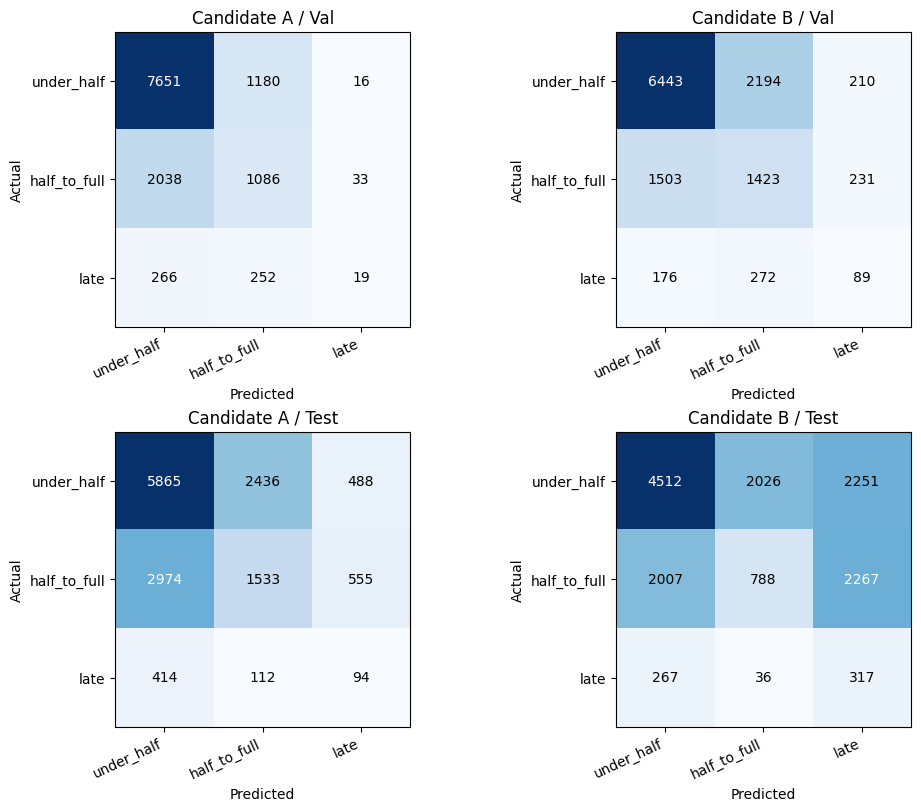

In [17]:
def plot_confusion_matrix(matrix, ax, title):
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(BANDS, rotation=25, ha="right")
    ax.set_yticks(range(3)); ax.set_yticklabels(BANDS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")

fig, axes = plt.subplots(2, len(candidate_rows), figsize=(5 * len(candidate_rows), 8), constrained_layout=True, squeeze=False)
for column, label in enumerate(candidate_rows):
    for row, split in enumerate(["Val", "Test"]):
        plot_confusion_matrix(candidate_results[label, split]["matrix"], axes[row, column], f"{label} / {split}")
plt.show()


### 12.1 Business Success Criteria and Threshold Analysis

For this revised experiment, assume that late precision must be at least 20% and late recall at least 30%. These are provisional business targets, not requirements validated against actual customer-service costs or capacity. A late alert requests priority review; it does not establish that an order will be late.

For each frozen candidate, use only the original Validation set to select the threshold with highest late recall among those achieving precision >=20%. Break recall ties with the higher threshold; report infeasibility without relaxing the target. Predict late when its score >= threshold; otherwise choose the higher-scoring under_half or half_to_full class. Retain ordinary three-class argmax as the before-adjustment comparison.

Freeze both thresholds before evaluating Test with the same fitted models, without refitting or changing CV selection. Validation operating-point results have selection optimism. Weighted scores are not calibrated absolute risks, and this remains a revised evaluation of historically viewed Test data.


,Candidate,Feasible precision threshold,Frozen threshold
0,Candidate A,True,0.277841
1,Candidate B,True,0.463277


,Candidate,Split,Rule,Threshold,Late AP,Late Precision,Late Recall,Late F1,Macro-F1,Alerts,Alert share,Both targets met
0,Candidate A,Val,Argmax,NaN,0.1230,0.2794,0.0354,0.0628,0.4198,68,0.0054,False
1,Candidate A,Val,Validation threshold,0.2778,0.1230,0.2011,0.1359,0.1622,0.4446,363,0.0289,False
2,Candidate A,Test,Argmax,NaN,0.0738,0.0827,0.1516,0.1070,0.3642,1137,0.0786,False
3,Candidate A,Test,Validation threshold,0.2778,0.0738,0.0597,0.2871,0.0989,0.3196,2981,0.2060,False
4,Candidate B,Val,Argmax,NaN,0.1217,0.1679,0.1657,0.1668,0.4434,530,0.0423,False
5,Candidate B,Val,Validation threshold,0.4633,0.1217,0.2017,0.1341,0.1611,0.4453,357,0.0285,False
6,Candidate B,Test,Argmax,NaN,0.0746,0.0656,0.5113,0.1162,0.2983,4835,0.3341,False
7,Candidate B,Test,Validation threshold,0.4633,0.0746,0.0616,0.2887,0.1015,0.3223,2908,0.2010,False


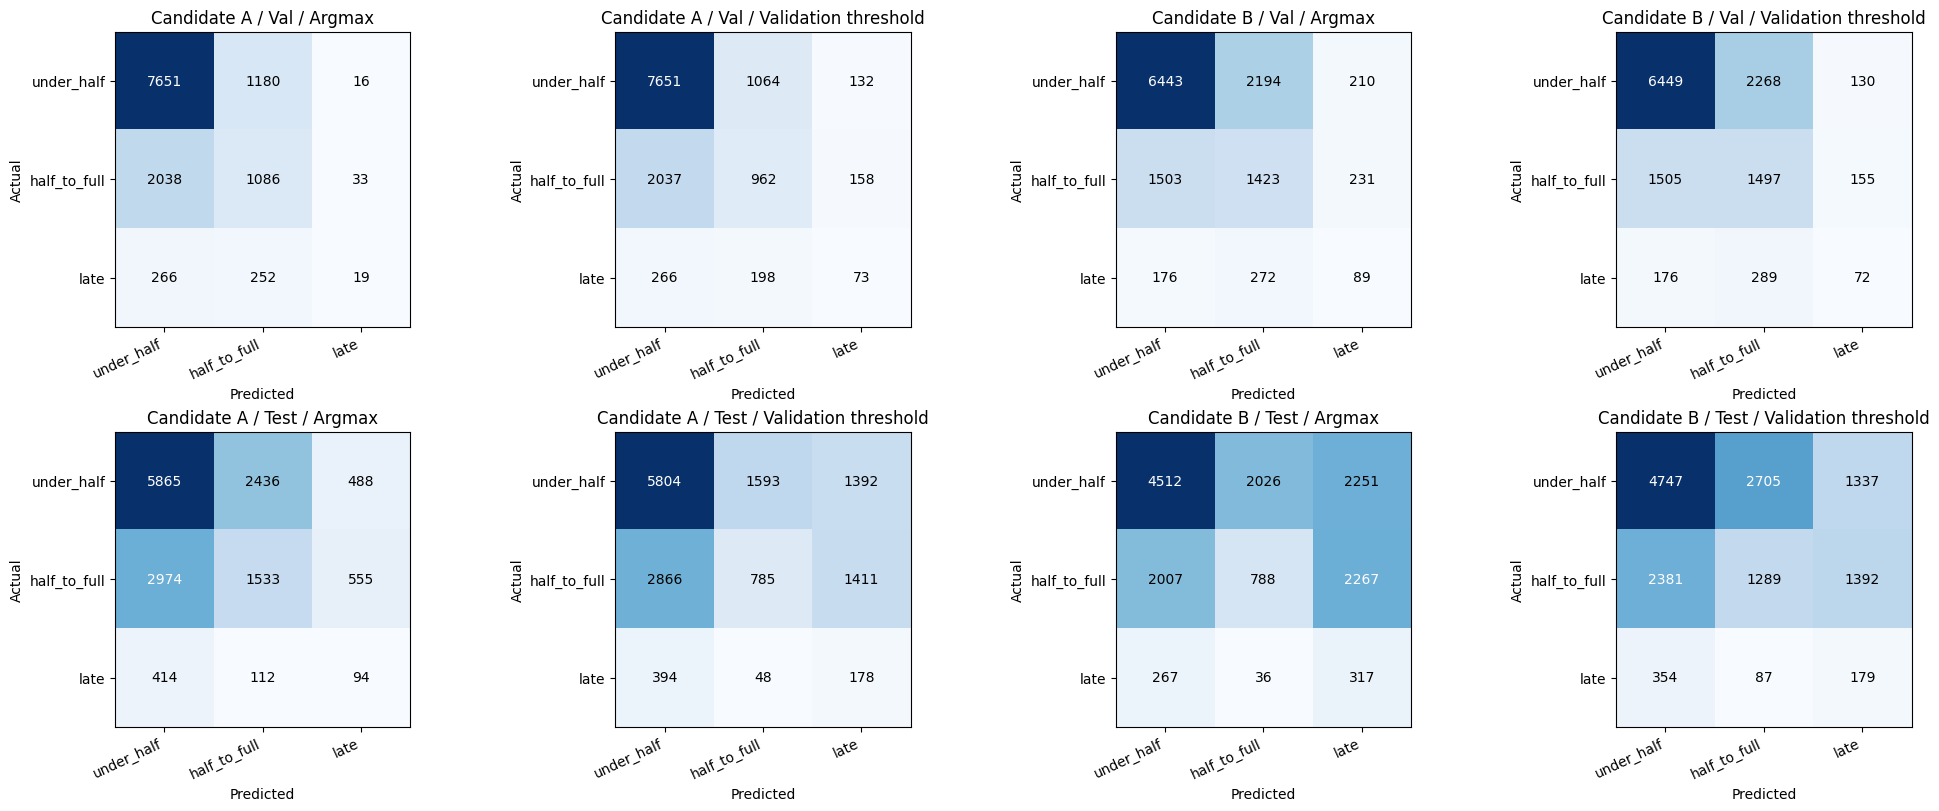

In [18]:
display(pd.DataFrame(threshold_selection_rows).round(6))

def evaluate_threshold_predictions(frame, probabilities, classes, threshold=None):
    late_column = np.flatnonzero(classes == "late").item()
    if threshold is None:
        pred = classes[probabilities.argmax(axis=1)]
    else:
        nonlate_columns = np.flatnonzero(classes != "late")
        pred = classes[nonlate_columns[
            probabilities[:, nonlate_columns].argmax(axis=1)
        ]].copy()
        pred[probabilities[:, late_column] >= threshold] = "late"
    report = classification_report(
        frame[TARGET], pred, labels=BANDS, output_dict=True, zero_division=0,
    )
    matrix = confusion_matrix(frame[TARGET], pred, labels=BANDS)
    alert_count = int((pred == "late").sum())
    assert matrix.sum() == len(frame)
    assert alert_count == matrix[:, BANDS.index("late")].sum()
    return {
        "Late AP": average_precision_score(
            frame[TARGET].eq("late"), probabilities[:, late_column],
        ),
        "Late Precision": report["late"]["precision"],
        "Late Recall": report["late"]["recall"],
        "Late F1": report["late"]["f1-score"],
        "Macro-F1": f1_score(
            frame[TARGET], pred, labels=BANDS, average="macro", zero_division=0,
        ),
        "Alerts": alert_count, "Alert share": alert_count / len(frame),
        "Both targets met": (report["late"]["precision"] >= MIN_LATE_PRECISION
                             and report["late"]["recall"] >= MIN_LATE_RECALL),
        "matrix": matrix,
    }

threshold_results, threshold_metric_rows = {}, []
for label, model in candidate_models.items():
    threshold = threshold_choices[label]
    if threshold is None:
        print(f"{label}: no Validation threshold attains late precision >=20%.")
    for split, frame in splits.items():
        classes, probabilities = (
            validation_scores[label] if split == "Val"
            else (np.asarray(model.classes_), model.predict_proba(frame[features]))
        )
        for rule, cutoff in [("Argmax", None), ("Validation threshold", threshold)]:
            if rule != "Argmax" and cutoff is None:
                continue
            result = evaluate_threshold_predictions(frame, probabilities, classes, cutoff)
            threshold_results[label, split, rule] = result
            if rule == "Argmax":
                assert np.array_equal(result["matrix"], candidate_results[label, split]["matrix"])
            threshold_metric_rows.append({
                "Candidate": label, "Split": split, "Rule": rule,
                "Threshold": np.nan if rule == "Argmax" else cutoff,
                **{k: v for k, v in result.items() if k != "matrix"},
            })
threshold_metrics = pd.DataFrame(threshold_metric_rows)
display(threshold_metrics.round(4))

fig, axes = plt.subplots(
    2, 2 * len(candidate_models), figsize=(10 * len(candidate_models), 8),
    constrained_layout=True, squeeze=False,
)
for column, label in enumerate(candidate_models):
    for row, split in enumerate(["Val", "Test"]):
        for offset, rule in enumerate(["Argmax", "Validation threshold"]):
            ax = axes[row, 2 * column + offset]
            key = (label, split, rule)
            if key in threshold_results:
                plot_confusion_matrix(
                    threshold_results[key]["matrix"], ax,
                    f"{label} / {split} / {rule}",
                )
            else:
                ax.axis("off")
                ax.set_title(f"{label} / {split}: no feasible threshold")
plt.show()


At the assumed precision floor, A selects threshold 0.2778406690 and B selects 0.4632771016. Validation precision/recall is 20.11%/13.59% for A and 20.17%/13.41% for B. These are the highest feasible recalls at precision >=20%; neither reaches 30%, so neither satisfies both targets on Validation.

With thresholds fixed, revised Test precision/recall is 5.97%/28.71% for A and 6.16%/28.87% for B. A raises 2,981 alerts (178 true late orders, 2,803 false alerts and 442 missed late orders); B raises 2,908 (179 true late orders, 2,729 false alerts and 441 misses). Both precision and recall targets fail on Test.

Relative to Test argmax results, A's threshold rule increases recall and alert volume but reduces precision and late F1. B's rule reduces alerts and recall, while precision and late F1 also fall; its Macro-F1 increases. Late AP is unchanged by thresholding within each model. The Validation trade-off does not transfer reliably to Test, and neither candidate demonstrates business readiness. Validation threshold-selection optimism and uncalibrated weighted scores remain limitations; Test results do not trigger threshold revision.


## 13. Conclusion

Candidate A (C=0.01, late weight 2.5) is selected by mean CV validation late AP=0.1023 +/- 0.0714. Candidate B (C=0.01, balanced) is the eligible late-sensitive alternative at 0.0899 +/- 0.0535. A's three validation-fold AP values are 0.0338, 0.0969, 0.1763. Fold class proportions differ and temporal variation is substantial; the mean ranking does not establish a stable operational improvement.

The latest CSV supplies 10 features, without raw coordinates. purchase_month and customer_state follow 03's categorical treatment; remaining selected fields use the existing numeric preprocessing. After original-Train refitting, A/B achieve Validation late AP=0.1230/0.1217 and revised Test late AP=0.0738/0.0746. Validation and Test results do not change the CV-selected configurations.

At the Validation-selected operating points, neither candidate simultaneously meets the assumed precision >=20% and recall >=30% targets on Validation or Test. Both models and thresholds were frozen before Test scoring, and the same fitted models are used for the operating-point evaluation.

Only the original Train set enters CV. Every fold fits a fresh preprocessing/model Pipeline on orders delivered before its validation start; whole purchase dates stay together. Feature names and their order come from 03's preselected CSV and are fixed across folds. This is not nested feature selection: data reused by 03 for selection, and any resulting look-ahead or overlap, limit independence. Original Validation and Test assignments remain unchanged. Test is a revised evaluation of historically viewed data, not a basis for choosing parameters or repeating the search.

